In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib

import testis_modeling as tm

In [172]:
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 12,              # base font size
    'xtick.labelsize': 7,        # x-axis tick label size
    'ytick.labelsize': 7,        # y-axis tick label size
    'axes.labelsize': 12,         # axis label size
    'axes.titlesize': 12,         # title size
    'legend.fontsize': 12,        # legend font size
    'figure.titlesize': 12        # figure title size
})

In [150]:
importlib.reload(tm.advanced_gillespie)

<module 'testis_modeling.advanced_gillespie' from '/Users/connor/Documents/github/gagnon/testis_modeling/advanced_gillespie.py'>

In [151]:
params = dict(
    n_stem = 200,
    n_clones = 10,
    r_event = 4,
    p_diff = 0,
    q_div = 0,
    r_decay = 0,
    sperm_per_diff = 1300
)

rng = np.random.default_rng(1)
init_freq = tm.advanced_gillespie.sample_ic(params['n_stem'], params['n_clones'], rng)

hmm = tm.advanced_gillespie.AdvancedTestisModel(**params, init_freq = init_freq)

sample_times = np.arange(1, 16)
n_sperm = 500

samples1, _, _ = hmm.simulate_gillespie(sample_times, n_sperm = n_sperm, rng = rng)
tm.data_processing.sort_results(samples1);

In [152]:
params = dict(
    n_stem = 200,
    n_clones = 10,
    r_event = 4,
    p_diff = 0.25,
    q_div = 0.25,
    r_decay = 0,
    sperm_per_diff = 1300
)

init_freq = tm.advanced_gillespie.sample_ic(params['n_stem'], params['n_clones'], rng)

hmm = tm.advanced_gillespie.AdvancedTestisModel(**params, init_freq = init_freq)

sample_times = np.arange(1, 16)
n_sperm = 500

samples2, _, _ = hmm.simulate_gillespie(sample_times, n_sperm = n_sperm, rng = rng)
tm.data_processing.sort_results(samples2);

In [153]:
params = dict(
    n_stem = 200,
    n_clones = 10,
    r_event = 4,
    p_diff = 0.5,
    q_div = 0.5,
    r_decay = 0,
    sperm_per_diff = 1300
)

init_freq = tm.advanced_gillespie.sample_ic(params['n_stem'], params['n_clones'], rng)

hmm = tm.advanced_gillespie.AdvancedTestisModel(**params, init_freq = init_freq)

sample_times = np.arange(1, 16)
n_sperm = 500

samples3, _, _ = hmm.simulate_gillespie(sample_times, n_sperm = n_sperm, rng = rng)
tm.data_processing.sort_results(samples3);

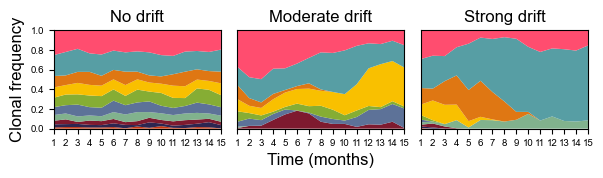

In [174]:
fig, ax = plt.subplots(1, 3, figsize = (6, 1.75))
tm.visualize.plot(samples1, ax = ax[0]);
ax[0].set_title('No drift')
ax[0].set_xlabel('')

tm.visualize.plot(samples2, ax = ax[1]);
ax[1].set_title('Moderate drift')
ax[1].set_xlabel('Time (months)')
ax[1].set_ylabel('')
ax[1].set_yticks([])

tm.visualize.plot(samples3, ax = ax[2]);
ax[2].set_title('Strong drift')
ax[2].set_xlabel('')
ax[2].set_ylabel('')
ax[2].set_yticks([])

fig.tight_layout(pad=0.5)
fig.savefig('../images/sample_sims.svg', bbox_inches='tight', format='svg')

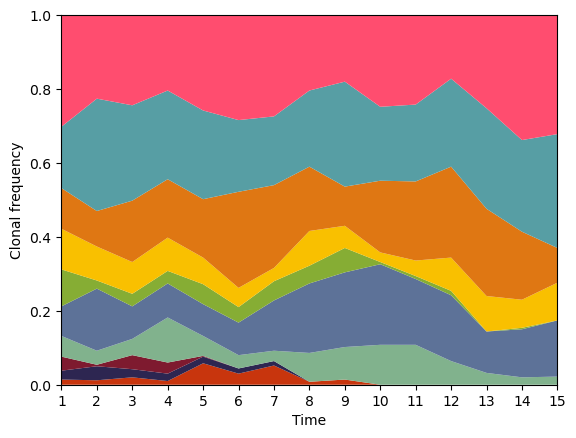

In [104]:
tm.visualize.plot(samples)

In [62]:
tm.advanced_gillespie.multinomial_numba(10, np.array(samples[0]['obs_result'][10]), rng)

array([0, 0, 0, 0, 3, 3, 2, 2, 0, 0])